In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from rake_nltk import Rake

In [2]:
nltk.download("stopwords")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [5]:
real = pd.read_csv("True.csv")
fake = pd.read_csv("Fake.csv")

In [6]:
# prepare the text
real_rake_text = " ".join(real["text"].head(500).fillna("").astype(str))

fake_rake_text = " ".join(fake["text"].head(500).fillna("").astype(str))

In [7]:
# extract RAKE keywords
real_rake = Rake()
real_rake.extract_keywords_from_text(real_rake_text)

fake_rake = Rake()
fake_rake.extract_keywords_from_text(fake_rake_text)

In [8]:
real_keywords = pd.DataFrame(
    real_rake.get_ranked_phrases_with_scores(),
    columns=["Score", "Keyword"]
).head(20)

fake_keywords = pd.DataFrame(
    fake_rake.get_ranked_phrases_with_scores(),
    columns=["Score", "Keyword"]
).head(20)

print("Top Keywords - Real News")
display(real_keywords)

print("Top Keywords - Fake News")
display(fake_keywords)

Top Keywords - Real News


,Score,Keyword
0,77.299567,"“ vulnerable ,” “ entitlement ,” “ diversity ,..."
1,70.774091,"coming days ,” white house spokesman hogan gid..."
2,68.629142,"terrorism threat ,” white house spokesman raj ..."
3,68.629142,"terrorism threat ,” white house spokesman raj ..."
4,60.694628,"mutually agreeable path forward ,” white house..."
5,53.677963,"discouraging ,” white house spokesman raj shah..."
6,53.610849,"let alone thoughtfully considered ,” said sena..."
7,51.810263,"investigation must continue unimpeded ,” house..."
8,50.913224,maintain “ impartiality ” even though “ juveni...
9,48.044717,congress past 2018 .” white house spokeswoman ...


Top Keywords - Fake News


,Score,Keyword
0,125.485714,es un acto de opresi n financiera que solo log...
1,73.674606,loser prince harry royal wedding royal family ...
2,73.448276,2017hypocrisy hypocrisy hypocrisy hypocrisy hy...
3,49.136022,harvey weinsteinfearless girlbirth control lau...
4,47.675993,2017featured image via video screen capture te...
5,45.152608,cowboys versus cardinals game featured dallas ...
6,44.044208,nascent modern nazi subculture appropriated ne...
7,43.416667,eliminar las leyes de cabotaje es inmoral
8,43.337150,passed laws allowing automatic guns cheri delb...
9,43.298739,featured image via screengrab tennessee republ...


In [9]:
# compare the keywords
real_top = set(real_keywords["Keyword"])
fake_top = set(fake_keywords["Keyword"])

common_keywords = real_top.intersection(fake_top)
real_specific = real_top.difference(fake_top)
fake_specific = fake_top.difference(real_top)

print("Common Keywords:")
print(sorted(common_keywords))

print("\nKeywords Specific to Real News Top 20:")
print(sorted(real_specific))

print("\nKeywords Specific to Fake News Top 20:")
print(sorted(fake_specific))

Common Keywords:
[]

Keywords Specific to Real News Top 20:
['.” state department spokeswoman heather nauert said kelly told tillerson ’', 'child tax credit ,” white house spokeswoman sarah sanders told reporters', 'coming days ,” white house spokesman hogan gidley told reporters aboard air force one', 'congress past 2018 .” white house spokeswoman sarah sanders said president donald trump', 'derisive nickname “ goofy kicking donald duck .”', 'discouraging ,” white house spokesman raj shah told reporters traveling', 'human rights zeid ra ’ ad al hussein said', 'investigation must continue unimpeded ,” house judiciary committee ranking democrat jerrold nadler said thursday', 'judgment ,” texas democratic party executive director crystal perkins said', 'let alone thoughtfully considered ,” said senate democratic leader chuck shumer', 'made today ,” attorney arnold reed told reporters outside conyers ’ home', 'maintain “ impartiality ” even though “ juvenile cases may present sympathetic 

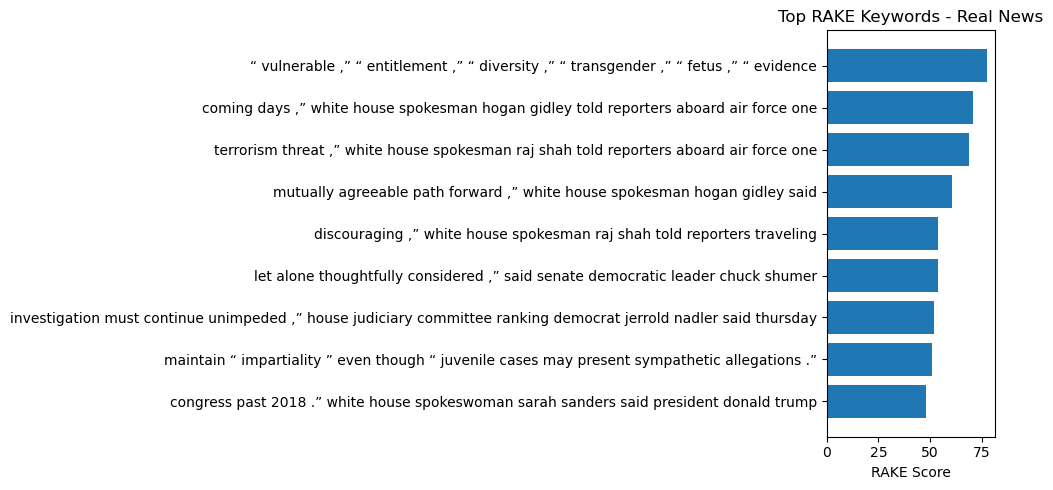

In [13]:
# top real keywords
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.barh(real_keywords["Keyword"].head(10),
         real_keywords["Score"].head(10))
plt.title("Top RAKE Keywords - Real News")
plt.xlabel("RAKE Score")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

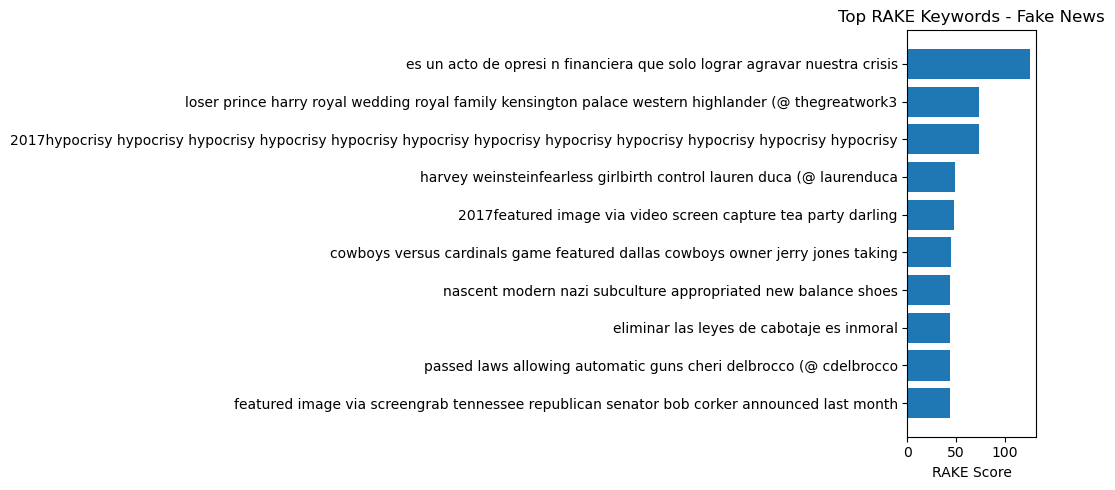

In [12]:
# top fake keywords
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 2)
plt.barh(fake_keywords["Keyword"].head(10),
         fake_keywords["Score"].head(10))
plt.title("Top RAKE Keywords - Fake News")
plt.xlabel("RAKE Score")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()